# Data pre-processing (Task 1)

In [5]:
# Libraries used in this notebook
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## 1. Loading the data

In [6]:
# Load the data and take a first look
data = pd.read_csv('Project_Data_EE4C12_S&S_EMG.csv')
data

,time,channel1,channel2,channel3,channel4,channel5,channel6,channel7,channel8,class,label
0,1,0.00001,-0.00002,-0.00001,-0.00003,0.00000,-0.00001,0.00000,-0.00001,0,1
1,5,0.00001,-0.00002,-0.00001,-0.00003,0.00000,-0.00001,0.00000,-0.00001,0,1
2,6,-0.00001,0.00001,0.00002,0.00000,0.00001,-0.00002,-0.00001,0.00001,0,1
3,7,-0.00001,0.00001,0.00002,0.00000,0.00001,-0.00002,-0.00001,0.00001,0,1
4,8,-0.00001,0.00001,0.00002,0.00000,0.00001,-0.00002,-0.00001,0.00001,0,1
...,...,...,...,...,...,...,...,...,...,...,...
4237902,50962,0.00001,-0.00001,-0.00002,-0.00004,-0.00012,0.00000,0.00002,0.00002,0,36
4237903,50963,0.00001,-0.00001,-0.00002,-0.00004,-0.00012,0.00000,0.00002,0.00002,0,36
4237904,50964,0.00001,-0.00001,-0.00002,-0.00004,-0.00012,0.00000,0.00002,0.00002,0,36
4237905,50965,0.00001,-0.00001,-0.00002,-0.00004,-0.00012,0.00000,0.00002,0.00002,0,36


In [7]:
# According to the project description the 'label' column is the subject number, so we rename it
data = data.rename(columns={'label': 'subject'})

channels = ['channel1', 'channel2', 'channel3', 'channel4', 'channel5', 'channel6', 'channel7', 'channel8']
class_names = {0: 'unmarked', 1: 'rest', 2: 'fist', 3: 'wrist flexion', 4: 'wrist extension',
               5: 'radial deviation', 6: 'ulnar deviation', 7: 'extended palm'}

print('Shape of the data:', data.shape)
print(data.dtypes)

Shape of the data: (4237907, 11)
time          int64
channel1    float64
channel2    float64
channel3    float64
channel4    float64
channel5    float64
channel6    float64
channel7    float64
channel8    float64
class         int64
subject       int64
dtype: object


In [8]:
# Check for missing values in each column
print(data.isna().sum())

time        0
channel1    0
channel2    0
channel3    0
channel4    0
channel5    0
channel6    0
channel7    0
channel8    0
class       0
subject     0
dtype: int64


In [9]:
# Basic statistics of the EMG channels
data[channels].describe()

,channel1,channel2,channel3,channel4,channel5,channel6,channel7,channel8
count,4.237907e+06,4.237907e+06,4.237907e+06,4.237907e+06,4.237907e+06,4.237907e+06,4.237907e+06,4.237907e+06
mean,-7.911478e-06,-9.416073e-06,-9.548730e-06,-9.637835e-06,-1.599724e-05,-1.085528e-05,-9.364639e-06,-9.696860e-06
std,1.631111e-04,1.192229e-04,1.241846e-04,2.257728e-04,2.724188e-04,2.151405e-04,1.527311e-04,1.720934e-04
min,-1.280000e-03,-1.280000e-03,-1.280000e-03,-1.280000e-03,-1.280000e-03,-1.280000e-03,-1.280000e-03,-1.280000e-03
25%,-3.000000e-05,-4.000000e-05,-4.000000e-05,-6.000000e-05,-8.000000e-05,-6.000000e-05,-4.000000e-05,-3.000000e-05
50%,-1.000000e-05,-1.000000e-05,-1.000000e-05,-1.000000e-05,-1.000000e-05,-1.000000e-05,-1.000000e-05,-1.000000e-05
75%,2.000000e-05,2.000000e-05,3.000000e-05,4.000000e-05,5.000000e-05,3.000000e-05,2.000000e-05,1.000000e-05
max,1.270000e-03,1.270000e-03,1.270000e-03,1.270000e-03,1.270000e-03,1.270000e-03,1.270000e-03,1.270000e-03


## 2. Class distribution

class
0    2725157
1     250055
2     243193
3     249494
4     251570
5     251733
6     253009
7      13696
Name: count, dtype: int64


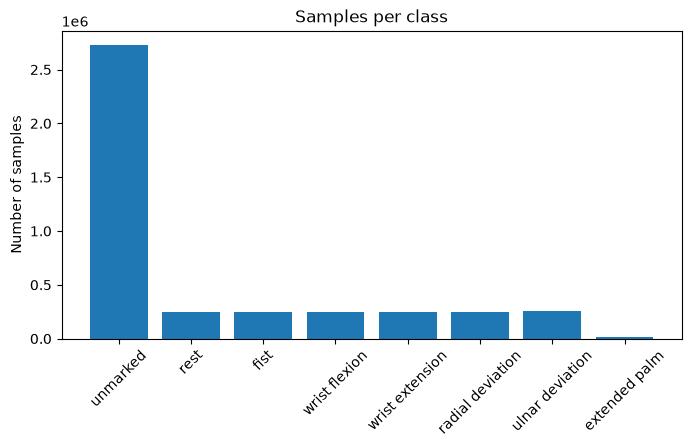

In [10]:
# Number of samples per class
counts = data['class'].value_counts().sort_index()
print(counts)

plt.figure(figsize=(8,4))
plt.bar([class_names[c] for c in counts.index], counts.values)
plt.xticks(rotation=45)
plt.ylabel('Number of samples')
plt.title('Samples per class')
plt.show()

In [11]:
# Number of samples per subject and class
per_subject = pd.crosstab(data['subject'], data['class'])
print('Subjects that performed class 7:', per_subject.index[per_subject[7] > 0].tolist())
per_subject

Subjects that performed class 7: [11, 30]


class,0,1,2,3,4,5,6,7
subject,,,,,,,,
1,78682,7311,6806,7329,6824,7075,7143,0
2,94654,7140,6777,6815,6812,6856,7372,0
3,67770,6443,6301,6486,6421,6278,6086,0
4,72578,6471,6598,6875,7193,7423,7060,0
5,68057,6506,6806,6874,6724,6098,6183,0
6,61128,5814,6243,6663,6688,7094,5989,0
7,82641,7523,7651,8383,8923,8414,9105,0
8,80264,6468,6537,5939,6027,6237,6476,0
9,90407,7083,6019,5838,5776,6050,6474,0


<br> Only 2 subjects performed class 7 (extended palm) <br>

## 3. Time and sampling rate

In [12]:
# Time difference (in ms) between consecutive samples, computed per subject
dt = data.groupby('subject')['time'].diff()
print(dt.value_counts().head(10))

time
1.0     4106924
2.0      108045
3.0       20752
4.0        1252
8.0         180
5.0         165
7.0         148
9.0         143
6.0          77
10.0         75
Name: count, dtype: int64


In [13]:
# A negative time step means the time restarts: this is where the second series of a subject begins
print('Number of time restarts:', (dt < 0).sum())

# Give every sample a series number (1 or 2) within its subject
data['series'] = (dt < 0).groupby(data['subject']).cumsum() + 1
print(data.groupby('subject')['series'].max().value_counts())

Number of time restarts: 36
series
2    36
Name: count, dtype: int64


In [14]:
# Duration of each series in seconds
duration = data.groupby(['subject', 'series'])['time'].agg(['min', 'max'])
duration['seconds'] = (duration['max'] - duration['min']) / 1000
print(duration['seconds'].describe())

count    72.000000
mean     61.263292
std       9.138398
min      47.446000
25%      53.699000
50%      60.163000
75%      65.473250
max      97.142000
Name: seconds, dtype: float64


In [15]:
# How often is a sample exactly the same as the previous one (on all 8 channels)?
same_as_prev = (data[channels].diff() == 0).all(axis=1)
print('Fraction of repeated samples:', same_as_prev.mean())

# Length of the runs of identical samples
run_id = (~same_as_prev).cumsum()
run_lengths = run_id.value_counts()
print('Run length -> number of runs')
print(run_lengths.value_counts().sort_index().head(10))

# Effective sampling rate = number of new (non-repeated) samples per second
total_seconds = dt[dt > 0].sum() / 1000
print('Effective sampling rate (Hz):', (~same_as_prev).sum() / total_seconds)

Fraction of repeated samples: 0.8914742584016119
Run length -> number of runs
count
1     144072
2      42501
3       1967
4       2629
5       5946
6      11215
7      14979
8      15053
9      14161
10      3426
Name: count, dtype: int64
Effective sampling rate (Hz): 104.26807606603283


## 4. Signal values

In [16]:
# The values look quantized: check how many different values a channel has
print('Number of unique values in channel1:', data['channel1'].nunique())
print(np.sort(data['channel1'].unique())[:10])

Number of unique values in channel1: 256
[-0.00128 -0.00127 -0.00126 -0.00125 -0.00124 -0.00123 -0.00122 -0.00121
 -0.0012  -0.00119]


In [19]:
# The sensor has a maximum value; samples at this value are clipped
max_value = data[channels].abs().max().max()
clipped = (data[channels].abs() >= max_value)
print('Max absolute value:', max_value)
print('Fraction of clipped samples per channel:')
print(clipped.mean())

Max absolute value: 0.00128
Fraction of clipped samples per channel:
channel1    0.000287
channel2    0.000129
channel3    0.000066
channel4    0.000731
channel5    0.001484
channel6    0.000382
channel7    0.000252
channel8    0.000392
dtype: float64


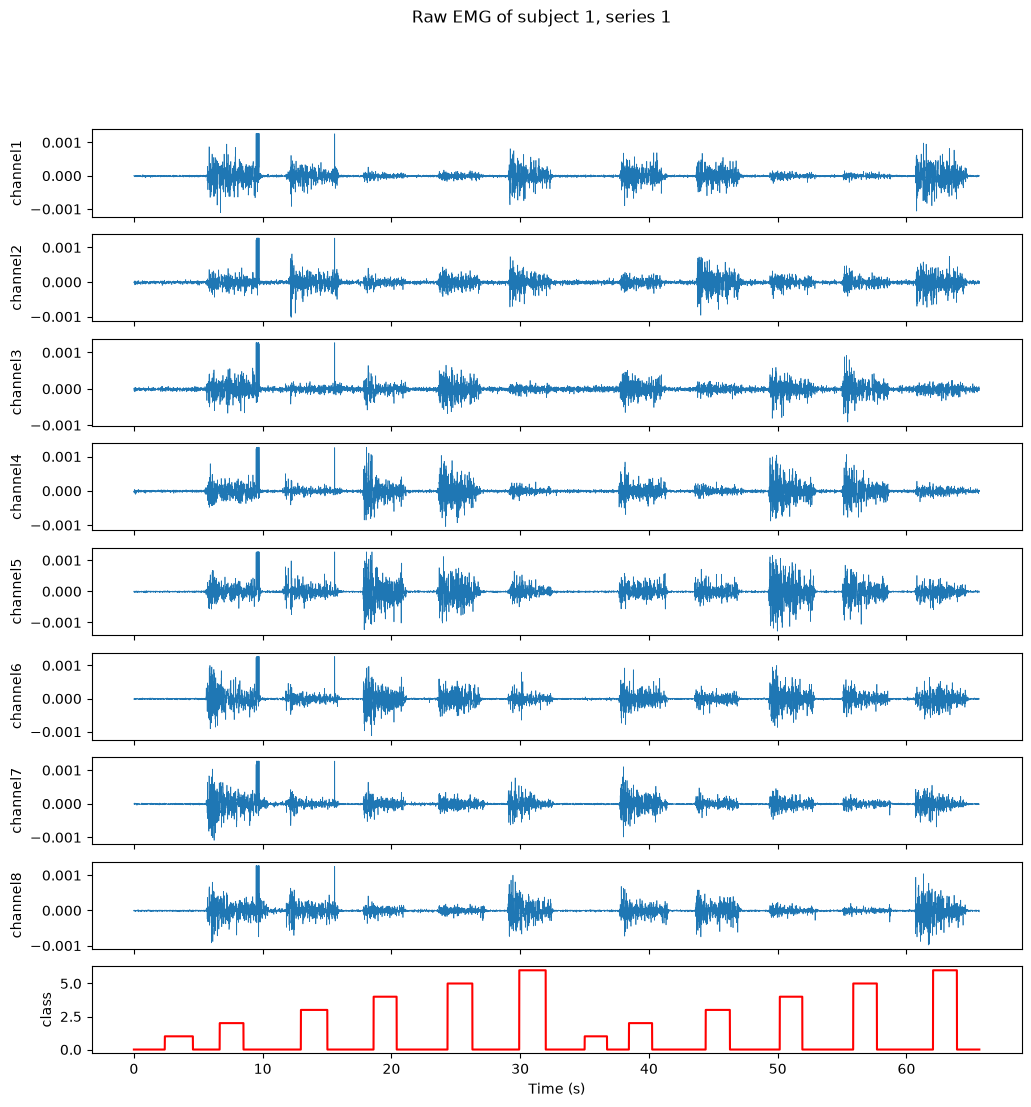

In [20]:
# Plot the raw signals of one subject (series 1) together with the class
s = data[(data['subject'] == 1) & (data['series'] == 1)]

fig, axes = plt.subplots(9, 1, figsize=(12,12), sharex=True)
for i, ch in enumerate(channels):
    axes[i].plot(s['time'] / 1000, s[ch], linewidth=0.5)
    axes[i].set_ylabel(ch)
axes[8].plot(s['time'] / 1000, s['class'], color='red')
axes[8].set_ylabel('class')
axes[8].set_xlabel('Time (s)')
plt.suptitle('Raw EMG of subject 1, series 1')
plt.show()

## 5. Gesture blocks

In [21]:
# Split the data into continuous blocks with the same class (new block at a class, series or subject change)
new_block = (data['class'] != data['class'].shift()) | (data['series'] != data['series'].shift()) | (data['subject'] != data['subject'].shift())
block_id = new_block.cumsum()

blocks = data.groupby(block_id).agg(subject=('subject', 'first'), series=('series', 'first'), cls=('class', 'first'),
                                     start=('time', 'first'), end=('time', 'last'), n_samples=('time', 'size'))
blocks['seconds'] = (blocks['end'] - blocks['start']) / 1000

# Duration of the gesture blocks per class (expected: about 3 seconds)
blocks.groupby('cls')['seconds'].describe()

,count,mean,std,min,25%,50%,75%,max
cls,,,,,,,,
0,940.0,3.023730,1.546262,0.659,2.08750,3.0335,3.79300,34.970
1,144.0,1.799153,0.395730,1.135,1.60350,1.7490,1.90450,4.596
2,144.0,1.746132,0.199073,1.118,1.61925,1.7345,1.84600,2.431
3,144.0,1.793806,0.298868,1.252,1.60600,1.7495,1.91025,3.278
4,144.0,1.806688,0.298462,1.343,1.62000,1.7860,1.89550,3.182
5,144.0,1.806201,0.293618,1.317,1.63600,1.7620,1.95100,2.821
6,144.0,1.817090,0.316997,1.270,1.60000,1.7780,1.96025,3.334
7,8.0,1.765875,0.135242,1.542,1.68125,1.7660,1.86800,1.950


In [23]:
# How many times is each gesture performed per subject and series?
blocks[blocks['cls'] != 0].groupby(['subject', 'series'])['cls'].count().value_counts()

cls
12    68
14     4
Name: count, dtype: int64

## 6. Can single samples separate the classes?

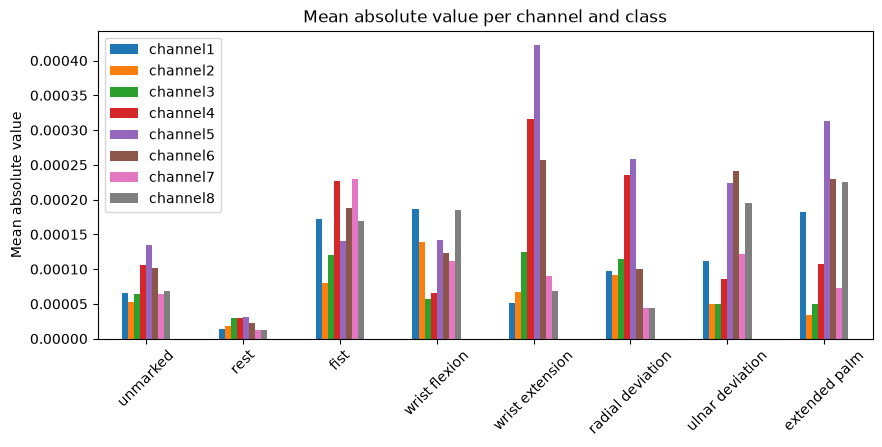

In [24]:
# Average signal strength (mean absolute value) per channel for each class
mav_per_class = data[channels].abs().groupby(data['class']).mean()
mav_per_class.index = [class_names[c] for c in mav_per_class.index]

mav_per_class.plot(kind='bar', figsize=(10,4))
plt.ylabel('Mean absolute value')
plt.title('Mean absolute value per channel and class')
plt.xticks(rotation=45)
plt.show()

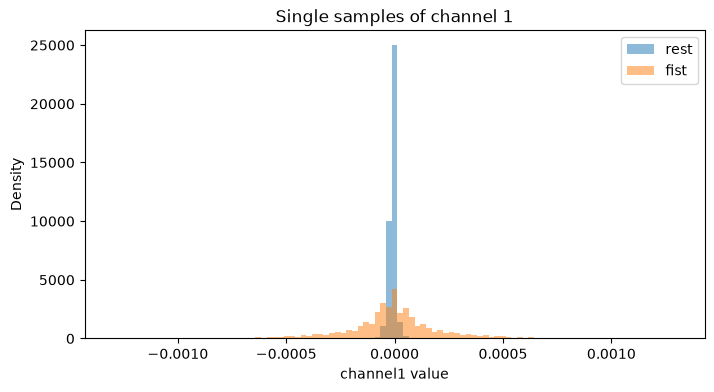

In [25]:
# Distribution of single samples of channel 1 for 'rest' and 'fist'
bins = np.linspace(-0.0013, 0.0013, 100)
plt.figure(figsize=(8,4))
plt.hist(data.loc[data['class'] == 1, 'channel1'], bins=bins, alpha=0.5, density=True, label='rest')
plt.hist(data.loc[data['class'] == 2, 'channel1'], bins=bins, alpha=0.5, density=True, label='fist')
plt.xlabel('channel1 value')
plt.ylabel('Density')
plt.title('Single samples of channel 1')
plt.legend()
plt.show()

## Observations

_Write down what you see in the outputs above (class balance, class 7, sampling rate, repeated samples, clipping, block durations, single samples vs. signal strength)._